# Khám phá dữ liệu – Chương 4
Đặt notebook cạnh `data_for_energyy.csv` rồi chạy lần lượt các ô. Hình lưu vào thư mục `hinh/`.
Thư viện: pandas, numpy, matplotlib, scikit-learn, statsmodels.

| Phần | Mục trong báo cáo | Kỹ thuật (bài học) |
|---|---|---|
| 1 | 4.1 Kiểu dữ liệu, chất lượng, ngoại lai, giá trị thiếu | Bài 2 |
| 2 | 4.2 Thống kê mô tả và phân phối | Bài 2 |
| 3 | 4.3 Chuỗi thời gian: tính dừng, phân rã | Bài 5 |
| 4 | 4.4 Quan hệ giữa biến: tương quan, hồi quy | Bài 3, Bài 4 |
| 5 | 4.5 Chọn đặc trưng và giảm chiều | Bài 3 |
| 6 | 4.6 Tự tương quan | Bài 5 |

Bài 6 (phân loại) và mất cân bằng lớp (SMOTE) của Bài 2 không áp dụng vì bài toán là hồi quy chuỗi thời gian. Bộ dữ liệu không có biến phân loại ngoài `precip_type:idx`.

## 0. Chuẩn bị

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.feature_selection import RFECV, VarianceThreshold
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf, adfuller, pacf

warnings.filterwarnings("ignore")
os.makedirs("hinh", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160

In [2]:
df = pd.read_csv("data_for_energyy.csv")
df["time"] = pd.to_datetime(df["time"], format="%d/%m/%Y %H:%M")
df = df.sort_values("time").reset_index(drop=True)

# Bốn đại lượng điện đo được
pv, wind, load, price = df["pv_production"], df["wind_production"], df["consumption"], df["spot_market_price"]
series = {"PV": pv, "Gió": wind, "Phụ tải": load, "Giá điện": price}
colors = {"PV": "#F58518", "Gió": "#4C78A8", "Phụ tải": "#54A24B", "Giá điện": "#B279A2"}
meteo = [c for c in df.columns if c not in ("time", "pv_production", "wind_production", "consumption", "spot_market_price")]

# Công suất gió âm cực trị (|giá trị| rất lớn): đặt NaN rồi nội suy tuyến tính
extreme = wind < -100
wind_clean = wind.where(~extreme)
wind_interp = wind_clean.interpolate()
hour, month = df["time"].dt.hour, df["time"].dt.to_period("M")


def comma(v, d=2):
    return f"{v:.{d}f}".replace(".", ",")

## 1. Kiểu dữ liệu, chất lượng và ngoại lai (Mục 4.1, Bài 2)
### 1.1 Kiểu dữ liệu

In [3]:
kinds = {"time": "khoảng (thời gian)", "precip_type:idx": "phân loại (nhãn số)"}
tab = pd.DataFrame({"dtype": df.dtypes.astype(str),
                    "số giá trị khác nhau": df.nunique(),
                    "loại": [kinds.get(c, "liên tục (số thực)") for c in df.columns]})
print(tab["loại"].value_counts().to_string())
print()
print(df["precip_type:idx"].value_counts().sort_index().to_string())
print("đại lượng điện đo được:", list(series), "| biến khí tượng:", len(meteo))

loại
liên tục (số thực)     42
khoảng (thời gian)      1
phân loại (nhãn số)     1

precip_type:idx
0    8918
1     246
2      10
3      18
đại lượng điện đo được: ['PV', 'Gió', 'Phụ tải', 'Giá điện'] | biến khí tượng: 39


### 1.2 Kích thước, giá trị thiếu, trùng lặp, cột hằng, bước thời gian

In [4]:
print("kích thước:", df.shape, "|", df["time"].min(), "->", df["time"].max())
print("số ngày:", round((df["time"].max() - df["time"].min()).total_seconds() / 86400 + 1 / 24, 2), "| số giờ:", len(df), "| 8760 giờ = 365 ngày")
print("ô trống:", int(df.isna().sum().sum()))
print("mốc thời gian trùng:", int(df["time"].duplicated().sum()), "| hàng trùng toàn bộ:", int(df.duplicated().sum()))
print("bước thời gian khác 1 giờ:", int((df["time"].diff().dropna() != pd.Timedelta(hours=1)).sum()))
print("cột hằng:", int((df.drop(columns="time").std() == 0).sum()))

kích thước: (9192, 44) | 2020-01-15 00:00:00 -> 2021-01-31 23:00:00
số ngày: 383.0 | số giờ: 9192 | 8760 giờ = 365 ngày
ô trống: 0
mốc thời gian trùng: 0 | hàng trùng toàn bộ: 0
bước thời gian khác 1 giờ: 0
cột hằng: 0


### 1.3 Công suất gió âm
Công suất phát không âm về mặt vật lý; các giá trị âm là nhiễu đo hoặc điện tự dùng của tua-bin.

In [5]:
small_neg = wind[(wind < 0) & ~extreme]
print("số giờ gió âm:", int((wind < 0).sum()), f"({(wind < 0).mean():.1%})")
print("âm nhỏ:", len(small_neg), f"giờ, từ {small_neg.min():.2f} đến {small_neg.max():.2f} kW, trung bình {small_neg.mean():.2f}")
print("cực trị:"); print(df.loc[extreme, ["time", "wind_production", "wind_speed_100m:ms"]].to_string(index=False))
print("độ nhọn dư của gió, có / không có cực trị:", round(wind.kurt(), 1), round(wind_clean.kurt(), 1))

số giờ gió âm: 4025 (43.8%)
âm nhỏ: 4023 giờ, từ -1.28 đến -0.01 kW, trung bình -0.30
cực trị:
               time  wind_production  wind_speed_100m:ms
2020-10-04 04:00:00         -566.340               6.800
2020-12-16 09:00:00         -582.200               4.900
độ nhọn dư của gió, có / không có cực trị: 18.2 6.0


### 1.4 Ngoại lai: z-score, IQR và Hampel (số giờ bị đánh dấu)

In [6]:
rows = {}
for name, x in series.items():
    z = ((x - x.mean()) / x.std()).abs() > 3
    q1, q3 = x.quantile(0.25), x.quantile(0.75)
    iqr = (x < q1 - 1.5 * (q3 - q1)) | (x > q3 + 1.5 * (q3 - q1))
    med = x.rolling(11, center=True, min_periods=1).median()
    mad = x.rolling(11, center=True, min_periods=1).apply(lambda w: np.median(np.abs(w - np.median(w))), raw=True)
    hampel = (x - med).abs() > 3 * 1.4826 * mad
    rows[name] = {"z-score > 3": z.sum(), "IQR": iqr.sum(), "Hampel": hampel.sum()}
outliers = pd.DataFrame(rows).T
display(outliers)
display((outliers / len(df) * 100).round(1).astype(str) + " %")

,z-score > 3,IQR,Hampel
PV,314,1468,456
Gió,246,1065,708
Phụ tải,231,362,459
Giá điện,212,587,168


,z-score > 3,IQR,Hampel
PV,3.4 %,16.0 %,5.0 %
Gió,2.7 %,11.6 %,7.7 %
Phụ tải,2.5 %,3.9 %,5.0 %
Giá điện,2.3 %,6.4 %,1.8 %


### Hình 1 – `eda_gio_am.png`: biểu đồ hộp, gió âm nhỏ, chuỗi gió

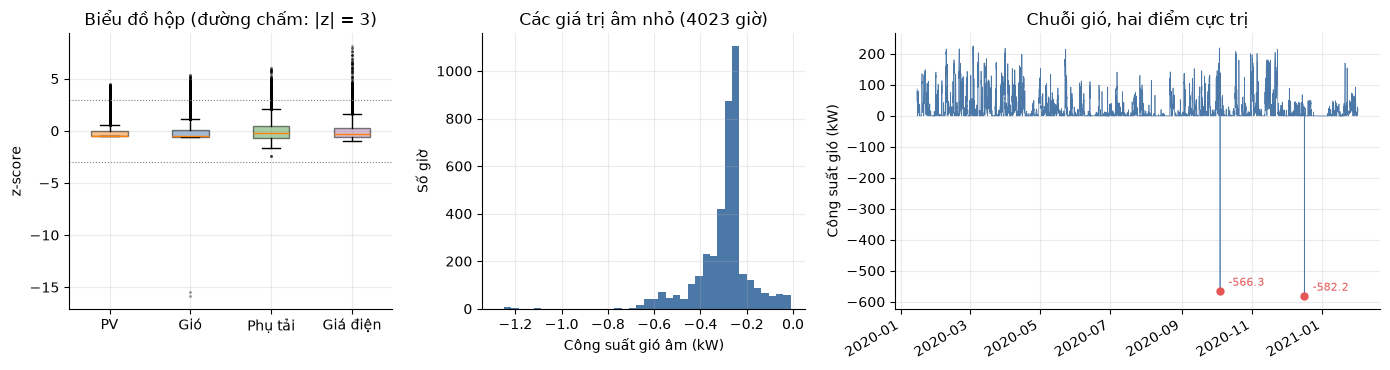

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1, 1.5]})
box = ax[0].boxplot([(x - x.mean()) / x.std() for x in series.values()], tick_labels=list(series),
                    flierprops=dict(marker=".", markersize=2, alpha=0.4), patch_artist=True)
for patch, name in zip(box["boxes"], series):
    patch.set(facecolor=colors[name], alpha=0.5)
ax[0].axhline(3, color="grey", ls=":", lw=0.8)
ax[0].axhline(-3, color="grey", ls=":", lw=0.8)
ax[0].set(ylabel="z-score", title="Biểu đồ hộp (đường chấm: |z| = 3)")
ax[1].hist(small_neg, bins=40, color=colors["Gió"])
ax[1].set(xlabel="Công suất gió âm (kW)", ylabel="Số giờ", title=f"Các giá trị âm nhỏ ({len(small_neg)} giờ)")
ax[2].plot(df["time"], wind, lw=0.5, color=colors["Gió"])
ax[2].scatter(df["time"][extreme], wind[extreme], color="#E45756", s=25, zorder=3)
for t, v in zip(df["time"][extreme], wind[extreme]):
    ax[2].annotate(f"{v:.1f}", (t, v), textcoords="offset points", xytext=(6, 4), fontsize=8, color="#E45756")
ax[2].set(ylabel="Công suất gió (kW)", title="Chuỗi gió, hai điểm cực trị")
plt.setp(ax[2].get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig("hinh/eda_gio_am.png", dpi=200)
plt.show()

### 1.5 Các bất thường khác (PV ban đêm, PV bằng 0 ban ngày, gió bằng 0)

In [8]:
sun = df["sun_elevation:d"]
print("PV > 0 khi góc cao mặt trời < 0:", int(((sun < 0) & (pv > 0)).sum()), "giờ")
print("PV = 0 khi góc cao mặt trời > 5:", int(((sun > 5) & (pv == 0)).sum()), "giờ")
print("ngày không có PV:", int((pv.groupby(df["time"].dt.date).max() == 0).sum()))
print("số giờ gió = 0:", int((wind == 0).sum()), "| tốc độ gió 100 m lớn nhất lúc đó:", df.loc[wind == 0, "wind_speed_100m:ms"].max())

PV > 0 khi góc cao mặt trời < 0: 202 giờ
PV = 0 khi góc cao mặt trời > 5: 145 giờ
ngày không có PV: 26
số giờ gió = 0: 172 | tốc độ gió 100 m lớn nhất lúc đó: 16.6


### 1.6 Giá trị thiếu: so sánh các phương pháp điền (Bài 2)
Bộ dữ liệu không có ô trống nên phương pháp điền được kiểm bằng mô phỏng: che ngẫu nhiên 1,5% số giờ (tỷ lệ thiếu mà bài nêu), điền lại bằng từng phương pháp rồi đo MAE trên các giờ bị che. Kịch bản (a): thiếu đơn lẻ, ngẫu nhiên hoàn toàn (MCAR). Kịch bản (b): thiếu theo khối 6 giờ liên tiếp. KNN (k = 5) và MICE (`IterativeImputer`) dùng thêm giờ trong ngày (sin, cos), nhiệt độ, bức xạ toàn phần và tốc độ gió 100 m.

In [9]:
rng = np.random.default_rng(0)
base = pd.DataFrame({"PV": pv, "Gió": wind_interp, "Phụ tải": load, "Giá điện": price})
aux = pd.DataFrame({"sin": np.sin(2 * np.pi * hour / 24), "cos": np.cos(2 * np.pi * hour / 24),
                    "temp": df["temp"], "rad": df["global_rad:W"], "v100": df["wind_speed_100m:ms"]})
n = len(df)


def mask_isolated(rate=0.015):
    return rng.choice(n, int(rate * n), replace=False)


def mask_blocks(rate=0.015, length=6):
    starts = rng.choice(n - length, int(rate * n / length), replace=False)
    return np.unique(np.concatenate([np.arange(s, s + length) for s in starts]))


def impute_all(y_masked):
    out = {"ffill": y_masked.ffill().bfill(), "bfill": y_masked.bfill().ffill(),
           "tuyến tính": y_masked.interpolate(limit_direction="both")}
    mat = pd.concat([y_masked.rename("y"), aux], axis=1)
    mu, sd = mat.mean(), mat.std()
    z = (mat - mu) / sd
    for name, imp in (("KNN", KNNImputer(n_neighbors=5)), ("MICE", IterativeImputer(max_iter=10, random_state=0))):
        out[name] = pd.Series(imp.fit_transform(z)[:, 0] * sd["y"] + mu["y"], index=y_masked.index)
    return out


res = {}
for scen, mk in (("(a) đơn lẻ", mask_isolated), ("(b) khối 6 giờ", mask_blocks)):
    for name in base:
        idx = mk()
        idx = idx[~extreme.values[idx]] if name == "Gió" else idx
        ym = base[name].copy()
        ym.iloc[idx] = np.nan
        res[(scen, name)] = {m: mean_absolute_error(base[name].iloc[idx], v.iloc[idx]) for m, v in impute_all(ym).items()}
        res[(scen, name)]["ĐLC của chuỗi"] = base[name].std()
display(pd.DataFrame(res).T)

ffill  bfill  tuyến tính    KNN   MICE  ĐLC của chuỗi
(a) đơn lẻ     PV        3.261  3.624       1.796  3.719  4.855         15.881
               Gió       9.553  8.061       7.176 14.248 17.403         36.969
               Phụ tải   3.033  3.571       2.654  3.985  4.513          8.332
               Giá điện  0.005  0.005       0.003  0.052  0.065          0.125
(b) khối 6 giờ PV       11.025 12.709       7.122  4.638  4.787         15.881
               Gió      22.795 14.179      13.100 21.729 22.050         36.969
               Phụ tải   4.436  7.066       4.764  3.620  4.116          8.332
               Giá điện  0.015  0.026       0.013  0.047  0.068          0.125

## 2. Thống kê mô tả và phân phối (Mục 4.2, Bài 2)

In [10]:
stats = pd.DataFrame({name: [x.mean(), x.std(), x.min(), x.quantile(0.25), x.median(), x.quantile(0.75), x.max(), x.skew()] for name, x in series.items()},
                     index=["TB", "ĐLC", "Nhỏ nhất", "Q1", "Trung vị", "Q3", "Lớn nhất", "Skew"]).T
display(stats)
print("PV bằng 0:", int((pv == 0).sum()), f"giờ ({(pv == 0).mean():.1%})")
print("tổng điện tiêu thụ:", round(load.sum()), "kWh | trung bình mỗi tuần:", round(load.sum() / (len(df) / 168)), "kWh")

,TB,ĐLC,Nhỏ nhất,Q1,Trung vị,Q3,Lớn nhất,Skew
PV,7.916,15.881,0.000,0.000,0.000,6.959,79.856,2.419
Gió,20.686,37.997,-582.200,-0.270,1.935,24.803,225.500,1.403
Phụ tải,20.211,8.332,0.048,14.661,18.764,23.742,70.367,1.898
Giá điện,0.123,0.125,0.000,0.043,0.088,0.157,1.141,2.836


PV bằng 0: 4847 giờ (52.7%)
tổng điện tiêu thụ: 185776 kWh | trung bình mỗi tuần: 3395 kWh


### Hình 2 – `eda_phanphoi.png`: biểu đồ tần suất của bốn đại lượng điện

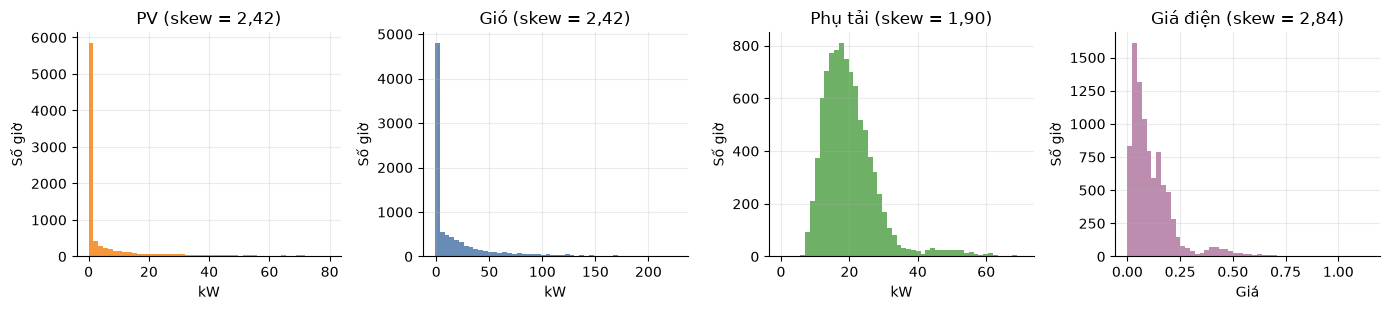

In [11]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, (name, x) in zip(ax, {**series, "Gió": wind_clean.dropna()}.items()):
    a.hist(x, bins=50, color=colors[name], alpha=0.85)
    a.set(title=f"{name} (skew = {comma(x.skew())})", xlabel="kW" if name != "Giá điện" else "Giá", ylabel="Số giờ")
fig.tight_layout()
fig.savefig("hinh/eda_phanphoi.png", dpi=200)
plt.show()

## 3. Chuỗi thời gian: diễn biến, tính dừng và phân rã (Mục 4.3, Bài 5)

In [12]:
display(pd.DataFrame({"PV lớn nhất": pv.groupby(month).max(), "PV TB": pv.groupby(month).mean(),
                      "Gió TB (bỏ cực trị)": wind_clean.groupby(month).mean(), "Phụ tải TB": load.groupby(month).mean(),
                      "Giá TB": price.groupby(month).mean()}))

,PV lớn nhất,PV TB,Gió TB (bỏ cực trị),Phụ tải TB,Giá TB
time,,,,,
2020-01,40.226,1.116,27.152,22.192,0.214
2020-02,60.439,3.852,32.851,23.297,0.139
2020-03,71.048,7.576,38.415,22.393,0.100
2020-04,79.856,11.262,28.867,21.097,0.053
2020-05,77.735,14.274,19.220,18.845,0.096
2020-06,77.439,19.614,9.025,15.849,0.034
2020-07,78.052,11.536,10.242,14.414,0.027
2020-08,72.056,13.443,7.728,13.647,0.068
2020-09,70.212,8.381,20.014,15.183,0.107


### Hình 3 – `eda_chuoi_thoigian.png`

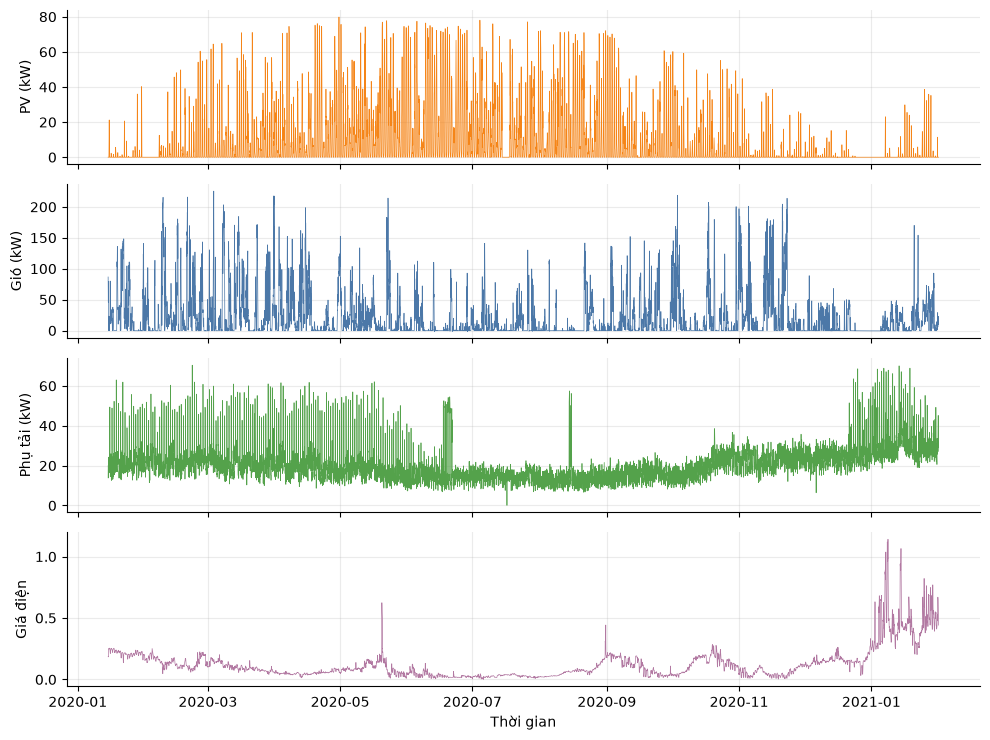

In [13]:
fig, ax = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
labels = ["PV (kW)", "Gió (kW)", "Phụ tải (kW)", "Giá điện"]
for a, label, (name, y) in zip(ax, labels, {**series, "Gió": wind_clean}.items()):
    a.plot(df["time"], y, lw=0.5, color=colors[name])
    a.set_ylabel(label)
ax[-1].set_xlabel("Thời gian")
fig.tight_layout()
fig.savefig("hinh/eda_chuoi_thoigian.png", dpi=200)
plt.show()

### 3.1 Phụ tải theo giai đoạn, theo giờ và theo thứ trong tuần

In [14]:
t = df["time"]
print("phụ tải TB ba giai đoạn:", [round(float(load[m].mean()), 2) for m in
      (t < "2020-06-16", (t >= "2020-06-16") & (t < "2020-12-01"), t >= "2020-12-01")])
print("giờ phụ tải > 45 kW:", int((load > 45).sum()), "| trong khung 17-19 giờ:", int(hour[load > 45].between(17, 19).sum()))
print("giờ PV trung bình cao nhất:", pv.groupby(hour).mean().idxmax(), "| phụ tải TB 18 giờ / 4 giờ:",
      load.groupby(hour).mean()[[18, 4]].round(1).tolist())
print("phụ tải TB theo thứ trong tuần (thứ hai = 0):", load.groupby(t.dt.dayofweek).mean().round(1).tolist())

phụ tải TB ba giai đoạn: [20.84, 16.94, 27.51]
giờ phụ tải > 45 kW: 236 | trong khung 17-19 giờ: 176
giờ PV trung bình cao nhất: 11 | phụ tải TB 18 giờ / 4 giờ: [30.1, 15.5]
phụ tải TB theo thứ trong tuần (thứ hai = 0): [20.0, 19.6, 20.1, 20.5, 20.4, 20.6, 20.1]


### 3.2 Tính dừng: thống kê theo ba đoạn bằng nhau và kiểm định ADF
ADF với giả thuyết không là có nghiệm đơn vị (chuỗi không dừng); p nhỏ cho thấy chuỗi dừng. Kiểm tra trên chuỗi gốc, sai phân bậc 1 và sai phân mùa chu kỳ 24 giờ.

In [15]:
ts = {"PV": pv, "Gió": wind_interp, "Phụ tải": load, "Giá điện": price}   # gió đã nội suy hai điểm cực trị
part = {}
for name, y in ts.items():
    thirds = np.array_split(y.values, 3)
    part[name] = {**{f"TB đoạn {i + 1}": c.mean() for i, c in enumerate(thirds)}, **{f"Var đoạn {i + 1}": c.var() for i, c in enumerate(thirds)}}
display(pd.DataFrame(part).T)
adf = {}
for name, y in ts.items():
    adf[name] = {"p gốc": adfuller(y)[1], "p sai phân 1": adfuller(y.diff().dropna())[1], "p sai phân mùa 24": adfuller(y.diff(24).dropna())[1]}
display(pd.DataFrame(adf).T)

,TB đoạn 1,TB đoạn 2,TB đoạn 3,Var đoạn 1,Var đoạn 2,Var đoạn 3
PV,7.559,13.594,2.593,226.976,399.307,69.591
Gió,30.058,12.723,19.666,1906.155,703.319,1337.978
Phụ tải,21.892,14.894,23.846,71.282,32.308,60.354
Giá điện,0.116,0.060,0.194,0.004,0.003,0.031


,p gốc,p sai phân 1,p sai phân mùa 24
PV,0.000,0.000,0.000
Gió,0.000,0.000,0.000
Phụ tải,0.003,0.000,0.000
Giá điện,0.046,0.000,0.000


### 3.3 Phân rã cộng tính và nhân tính, chu kỳ 24 giờ

In [16]:
rows = {}
for name, y in ts.items():
    add = seasonal_decompose(y.values, model="additive", period=24)
    ok = ~np.isnan(add.resid)
    row = {"S cộng (%)": np.var(add.seasonal[ok]) / y.values[ok].var() * 100,
           "T cộng (%)": np.var(add.trend[ok]) / y.values[ok].var() * 100,
           "R cộng (%)": np.var(add.resid[ok]) / y.values[ok].var() * 100,
           "RMSE cộng": np.sqrt(np.mean((y.values[ok] - add.trend[ok] - add.seasonal[ok]) ** 2))}
    if (y > 0).all():                      # phân rã nhân tính chỉ áp dụng khi chuỗi luôn dương
        mul = seasonal_decompose(y.values, model="multiplicative", period=24)
        row["RMSE nhân"] = np.sqrt(np.mean((y.values[ok] - mul.trend[ok] * mul.seasonal[ok]) ** 2))
    else:
        row["RMSE nhân"] = np.nan          # PV có giá trị 0, gió có giá trị âm hoặc 0
    rows[name] = row
display(pd.DataFrame(rows).T)

,S cộng (%),T cộng (%),R cộng (%),RMSE cộng,RMSE nhân
PV,34.674,23.496,40.686,10.140,NaN
Gió,0.369,52.902,37.236,22.577,NaN
Phụ tải,18.887,39.246,41.651,5.373,5.248
Giá điện,0.896,92.214,5.496,0.029,NaN


### Hình 4 – `eda_chu_ky_ngay.png`: thành phần chu kỳ 24 giờ (trung bình theo giờ)

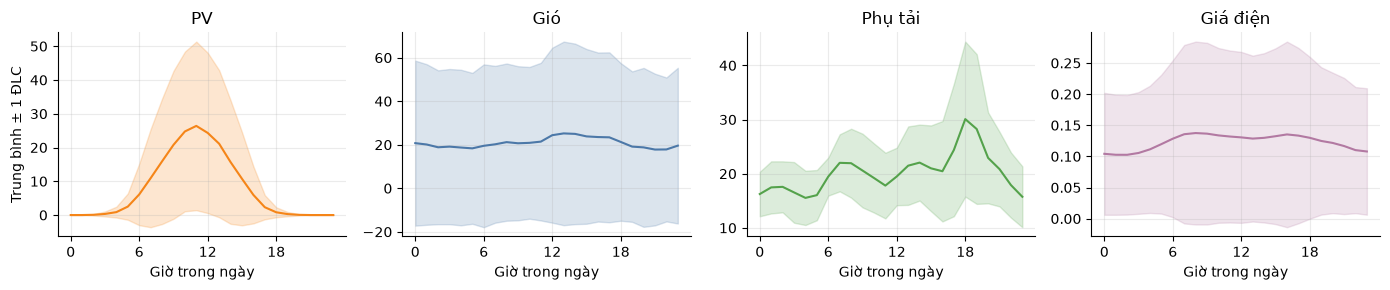

In [17]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3.0), sharex=True)
for a, (name, y) in zip(ax, ts.items()):
    prof = y.groupby(hour).agg(["mean", "std"])
    a.plot(prof.index, prof["mean"], color=colors[name])
    a.fill_between(prof.index, prof["mean"] - prof["std"], prof["mean"] + prof["std"], color=colors[name], alpha=0.2)
    a.set(title=name, xlabel="Giờ trong ngày", xticks=range(0, 24, 6))
ax[0].set_ylabel("Trung bình ± 1 ĐLC")
fig.tight_layout()
fig.savefig("hinh/eda_chu_ky_ngay.png", dpi=200)
plt.show()

## 4. Quan hệ giữa các biến: tương quan và hồi quy (Mục 4.4, Bài 3 và Bài 4)
### 4.1 Hồi quy đơn và đa thức: R² trong mẫu và ngoài mẫu (30% cuối theo thời gian)
R² ngoài mẫu dùng để nhận diện thiếu khớp (bậc thấp, cả hai R² thấp) và quá khớp (bậc cao, R² trong mẫu tăng còn R² ngoài mẫu giảm).

In [18]:
ok = ~extreme
cut = int(0.7 * len(df))                      # chỉ để đánh giá ngoài mẫu trong EDA, không phải chia tập của mô hình
pairs = [("PV ~ bức xạ tổng", df["global_rad:W"], pv, 1, "Bức xạ tổng (W/m²)", "PV (kW)", "PV", 5),
         ("Gió ~ tốc độ gió 100 m", df["wind_speed_100m:ms"].where(ok), wind.where(ok), 3, "Tốc độ gió 100 m (m/s)", "Gió (kW)", "Gió", 6),
         ("Giá ~ nhiệt độ", df["temp"], price, 2, "Nhiệt độ (°C)", "Giá điện", "Giá điện", 4)]


def poly_fit(x, y, degree, train=None):
    d = pd.concat([x, y], axis=1).dropna()
    X, Y = d.iloc[:, [0]].values, d.iloc[:, 1].values
    tr = d.index < cut if train is None else train
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression())
    model.fit(X[tr], Y[tr])
    return model, model.score(X[tr], Y[tr]), model.score(X[~tr], Y[~tr]), mean_squared_error(Y[~tr], model.predict(X[~tr])), mean_absolute_error(Y[~tr], model.predict(X[~tr]))


rows = {}
for title, x, y, _, _, _, _, maxd in pairs:
    rows[title] = {"Pearson": x.corr(y)}
    for d in range(1, maxd + 1):
        _, r2_tr, r2_te, mse, mae = poly_fit(x, y, d)
        rows[title][f"bậc {d}: R² trong / ngoài"] = f"{r2_tr:.3f} / {r2_te:.3f}"
display(pd.DataFrame(rows).T)

,Pearson,bậc 1: R² trong / ngoài,bậc 2: R² trong / ngoài,bậc 3: R² trong / ngoài,bậc 4: R² trong / ngoài,bậc 5: R² trong / ngoài,bậc 6: R² trong / ngoài
PV ~ bức xạ tổng,0.863,0.743 / 0.425,0.745 / 0.409,0.745 / 0.413,0.745 / 0.404,0.745 / 0.406,NaN
Gió ~ tốc độ gió 100 m,0.597,0.387 / 0.272,0.399 / 0.292,0.431 / 0.272,0.436 / 0.279,0.436 / 0.281,0.436 / 0.281
Giá ~ nhiệt độ,-0.607,0.235 / -0.089,0.240 / -0.017,0.241 / -0.069,0.243 / -0.126,NaN,NaN


### Hình 5 – `eda_quanhe_vatly.png`: ba quan hệ chính và đường hồi quy (toàn bộ mẫu)

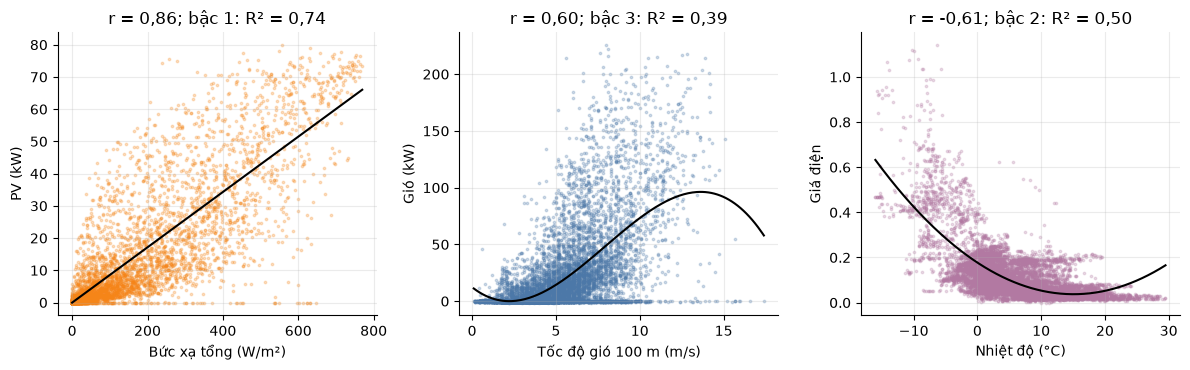

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
for a, (title, x, y, degree, xlabel, ylabel, name, _) in zip(ax, pairs):
    d = pd.concat([x, y], axis=1).dropna()
    X, Y = d.iloc[:, 0], d.iloc[:, 1]
    model = make_pipeline(StandardScaler(), PolynomialFeatures(degree), LinearRegression()).fit(X.values.reshape(-1, 1), Y)
    grid = np.linspace(X.min(), X.max(), 200)
    a.scatter(X, Y, s=3, alpha=0.25, color=colors[name])
    a.plot(grid, model.predict(grid.reshape(-1, 1)), color="black", lw=1.5)
    a.set(xlabel=xlabel, ylabel=ylabel, title=f"r = {comma(X.corr(Y))}; bậc {degree}: R² = {comma(model.score(X.values.reshape(-1, 1), Y))}")
fig.tight_layout()
fig.savefig("hinh/eda_quanhe_vatly.png", dpi=200)
plt.show()

### Hình 6 – `eda_bac_da_thuc.png`: R² trong mẫu và ngoài mẫu theo bậc đa thức

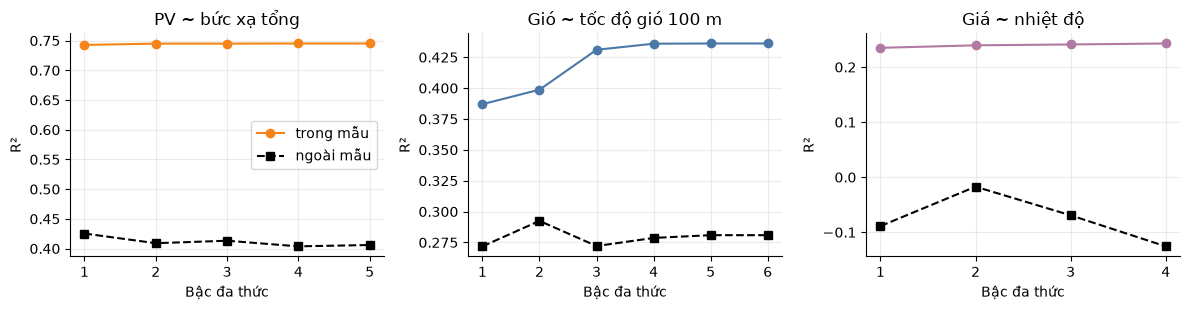

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, (title, x, y, _, _, _, name, maxd) in zip(ax, pairs):
    deg = range(1, maxd + 1)
    r = [poly_fit(x, y, d)[1:3] for d in deg]
    a.plot(deg, [v[0] for v in r], "o-", color=colors[name], label="trong mẫu")
    a.plot(deg, [v[1] for v in r], "s--", color="black", label="ngoài mẫu")
    a.set(title=title, xlabel="Bậc đa thức", ylabel="R²", xticks=list(deg))
ax[0].legend()
fig.tight_layout()
fig.savefig("hinh/eda_bac_da_thuc.png", dpi=200)
plt.show()

### 4.2 Hồi quy tuyến tính đa biến (R², MSE, MAE ngoài mẫu)

In [21]:
sets = {"PV": (pv, ["global_rad:W", "direct_rad:W", "diffuse_rad:W", "temp", "effective_cloud_cover:p", "relative_humidity_2m:p"]),
        "Gió": (wind.where(ok), ["wind_speed_10m:ms", "wind_speed_50m:ms", "wind_speed_100m:ms", "wind_dir_10m:d", "temp"])}
rows = {}
for name, (y, cols) in sets.items():
    d = pd.concat([df[cols], y.rename("y")], axis=1).dropna()
    tr = d.index < cut
    mdl = make_pipeline(StandardScaler(), LinearRegression()).fit(d.loc[tr, cols], d.loc[tr, "y"])
    pred = mdl.predict(d.loc[~tr, cols])
    rows[name] = {"R² trong mẫu": mdl.score(d.loc[tr, cols], d.loc[tr, "y"]), "R² ngoài mẫu": mdl.score(d.loc[~tr, cols], d.loc[~tr, "y"]),
                  "MSE ngoài mẫu": mean_squared_error(d.loc[~tr, "y"], pred), "MAE ngoài mẫu": mean_absolute_error(d.loc[~tr, "y"], pred)}
display(pd.DataFrame(rows).T)

,R² trong mẫu,R² ngoài mẫu,MSE ngoài mẫu,MAE ngoài mẫu
PV,0.753,0.422,23.611,2.368
Gió,0.401,0.261,963.234,21.609


### 4.3 Hệ số tương quan chọn lọc và số mũ cắt gió

In [22]:
print("gió - tốc độ gió 10/50/100 m:", [round(float(wind.corr(df[f"wind_speed_{h}m:ms"])), 3) for h in (10, 50, 100)])
print("gió - PV:", round(wind.corr(pv), 2), "| gió - phụ tải:", round(wind.corr(load), 2),
      "| PV - độ ẩm 2 m:", round(pv.corr(df["relative_humidity_2m:p"]), 2), "| PV - phụ tải:", round(pv.corr(load), 2))
print("giá - nhiệt độ:", round(price.corr(df["temp"]), 2), "| giá - phụ tải:", round(price.corr(load), 2),
      "| phụ tải - nhiệt độ:", round(load.corr(df["temp"]), 2))
alpha = lambda hi, lo, k: round((np.log(df[f"wind_speed_{hi}m:ms"] / df[f"wind_speed_{lo}m:ms"]) / np.log(k)).median(), 2)
print("số mũ lũy thừa (trung vị) 10-50 m, 50-100 m:", alpha(50, 10, 5), alpha(100, 50, 2))
jan = df["time"] >= "2021-01-01"
print("nhiệt độ TB tháng 1/2021 và phần còn lại:", round(df.loc[jan, "temp"].mean(), 1), round(df.loc[~jan, "temp"].mean(), 1))

gió - tốc độ gió 10/50/100 m: [0.544, 0.567, 0.579]
gió - PV: -0.02 | gió - phụ tải: 0.05 | PV - độ ẩm 2 m: -0.56 | PV - phụ tải: -0.16
giá - nhiệt độ: -0.61 | giá - phụ tải: 0.43 | phụ tải - nhiệt độ: -0.48
số mũ lũy thừa (trung vị) 10-50 m, 50-100 m: 0.2 0.24
nhiệt độ TB tháng 1/2021 và phần còn lại: -5.9 6.8


## 5. Chọn đặc trưng và giảm chiều (Mục 4.5, Bài 3)
Mục tiêu là PV và gió (hai đại lượng bài dự báo bằng XGBoost). Đặc trưng ứng viên gồm 39 biến khí tượng và giờ trong ngày (sin, cos). Phụ tải và giá điện không xét vì bài dự báo hai đại lượng này từ trạng thái và chuỗi giá.
### 5.1 Bộ lọc: ngưỡng phương sai và tương quan cặp

In [23]:
X_all = pd.concat([df[meteo], aux[["sin", "cos"]]], axis=1)
vt = VarianceThreshold(0.01).fit(MinMaxScaler().fit_transform(X_all))
print("số đặc trưng:", X_all.shape[1], "| phương sai (sau min-max) < 0,01:", [c for c, k in zip(X_all.columns, vt.get_support()) if not k])
cm = X_all.corr().abs()
upper = cm.where(np.triu(np.ones(cm.shape), 1).astype(bool))
pairs_hi = upper.stack()
print(f"cặp |r| > 0,95: {(pairs_hi > 0.95).sum()} / {len(pairs_hi)} | |r| > 0,90: {(pairs_hi > 0.90).sum()}")
drop = [c for c in upper.columns if (upper[c] > 0.95).any()]
print("số đặc trưng còn lại sau khi bỏ cột có |r| > 0,95 với cột đứng trước:", X_all.shape[1] - len(drop))

số đặc trưng: 41 | phương sai (sau min-max) < 0,01: ['precip_1h:mm', 'precip_type:idx']
cặp |r| > 0,95: 32 / 1681 | |r| > 0,90: 53
số đặc trưng còn lại sau khi bỏ cột có |r| > 0,95 với cột đứng trước: 21


### 5.2 Bọc (RFECV), nhúng (LASSO, độ quan trọng rừng ngẫu nhiên)

In [24]:
targets = {"PV": pv, "Gió": wind.where(ok)}
cv = TimeSeriesSplit(n_splits=3)
sel = {}
imp_rf = {}
for name, y in targets.items():
    d = pd.concat([X_all, y.rename("y")], axis=1).dropna()
    Xd, yd = d[X_all.columns], d["y"]
    rf = RandomForestRegressor(n_estimators=60, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=0)
    rfecv = RFECV(rf, step=3, cv=cv, scoring="neg_mean_absolute_error", min_features_to_select=3, n_jobs=1).fit(Xd, yd)
    lasso = LassoCV(cv=cv, random_state=0, max_iter=20000).fit(StandardScaler().fit_transform(Xd), yd)
    rf_full = rf.fit(Xd, yd)
    imp = pd.Series(rf_full.feature_importances_, index=Xd.columns).sort_values(ascending=False)
    imp_rf[name] = imp
    sel[name] = {"RFECV: số đặc trưng giữ lại": int(rfecv.n_features_),
                 "LASSO: số hệ số khác 0": int((np.abs(lasso.coef_) > 1e-8).sum()),
                 "RF: 3 đặc trưng đầu": ", ".join(imp.index[:3]),
                 "RF: tổng độ quan trọng 3 đầu": round(float(imp.iloc[:3].sum()), 3)}
    print(name, "- RFECV giữ:", ", ".join(Xd.columns[rfecv.support_]))
display(pd.DataFrame(sel).T)

PV - RFECV giữ: direct_rad:W, global_rad:W, sun_azimuth:d, medium_cloud_cover:p, total_cloud_cover:p, dew_point_2m:C, wind_speed_100m:ms, cos
Gió - RFECV giữ: sun_azimuth:d, sun_elevation:d, low_cloud_cover:p, high_cloud_cover:p, temp, dew_point_2m:C, wind_dir_2m:d, t_10m:C, wind_dir_10m:d, relative_humidity_50m:p, wind_speed_50m:ms, wind_dir_50m:d, t_100m:C, relative_humidity_100m:p, dew_point_100m:C, wind_speed_100m:ms, wind_dir_100m:d


,RFECV: số đặc trưng giữ lại,LASSO: số hệ số khác 0,RF: 3 đặc trưng đầu,RF: tổng độ quan trọng 3 đầu
PV,8,3,"global_rad:W, direct_rad:W, sun_azimuth:d",0.851
Gió,17,2,"wind_speed_100m:ms, wind_dir_100m:d, relative_...",0.568


### 5.3 Trích xuất đặc trưng: PCA trên 39 biến khí tượng (đã chuẩn hóa)

In [25]:
pca = PCA().fit(StandardScaler().fit_transform(df[meteo]))
cum = np.cumsum(pca.explained_variance_ratio_)
print("phương sai của thành phần 1, 2, 3:", np.round(pca.explained_variance_ratio_[:3], 3).tolist())
print("số thành phần cho 90% / 95% / 99% phương sai:", [int(np.argmax(cum >= q)) + 1 for q in (0.90, 0.95, 0.99)])

phương sai của thành phần 1, 2, 3: [0.326, 0.167, 0.139]
số thành phần cho 90% / 95% / 99% phương sai: [8, 11, 16]


### Hình 7 – `eda_chon_dac_trung.png`: độ quan trọng đặc trưng (rừng ngẫu nhiên) và phương sai tích lũy của PCA

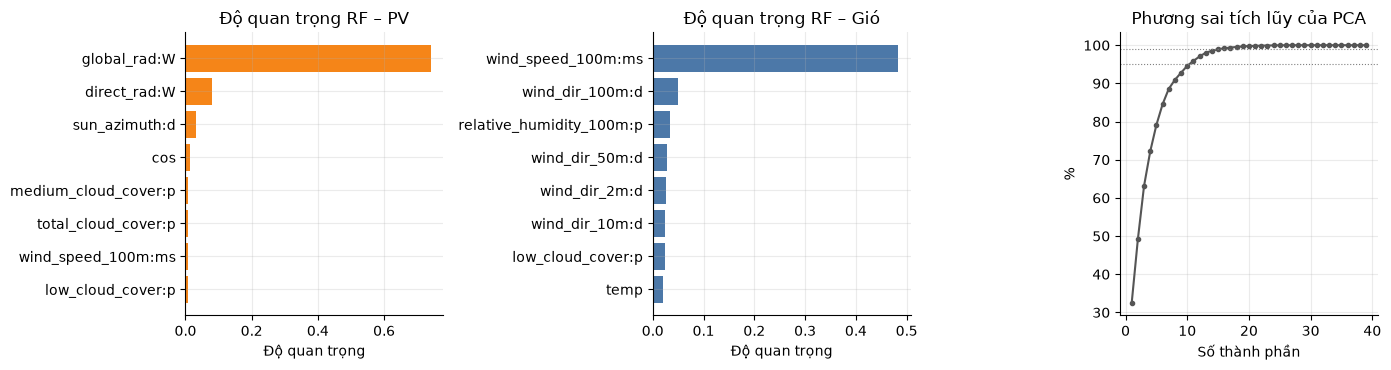

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, name in zip(ax[:2], targets):
    top = imp_rf[name].head(8)[::-1]
    a.barh(top.index, top.values, color=colors[name])
    a.set(title=f"Độ quan trọng RF – {name}", xlabel="Độ quan trọng")
ax[2].plot(range(1, len(cum) + 1), cum * 100, "o-", ms=3, color="#555555")
for q in (95, 99):
    ax[2].axhline(q, color="grey", ls=":", lw=0.8)
ax[2].set(title="Phương sai tích lũy của PCA", xlabel="Số thành phần", ylabel="%")
fig.tight_layout()
fig.savefig("hinh/eda_chon_dac_trung.png", dpi=200)
plt.show()

## 6. Tự tương quan (Mục 4.6, Bài 5)

In [27]:
acfs = {name: acf(y, nlags=168, fft=True) for name, y in ts.items()}
pacfs = {name: pacf(y, nlags=48) for name, y in ts.items()}
display(pd.DataFrame({name: v[[1, 24, 168]] for name, v in acfs.items()}, index=["ACF trễ 1 giờ", "ACF trễ 24 giờ", "ACF trễ 168 giờ"]).T)
display(pd.DataFrame({name: v[[1, 2, 24]] for name, v in pacfs.items()}, index=["PACF trễ 1", "PACF trễ 2", "PACF trễ 24"]).T)
print("ngưỡng ý nghĩa 95% ≈ ±", round(1.96 / np.sqrt(len(df)), 3))

,ACF trễ 1 giờ,ACF trễ 24 giờ,ACF trễ 168 giờ
PV,0.910,0.707,0.615
Gió,0.884,0.178,0.103
Phụ tải,0.697,0.674,0.571
Giá điện,0.991,0.888,0.665


,PACF trễ 1,PACF trễ 2,PACF trễ 24
PV,0.911,-0.299,-0.002
Gió,0.884,0.022,-0.003
Phụ tải,0.697,-0.047,0.283
Giá điện,0.991,-0.318,-0.076


ngưỡng ý nghĩa 95% ≈ ± 0.02


### Hình 8 – `eda_tutuongquan.png`: ACF (đến trễ 168 giờ) và PACF (đến trễ 48 giờ)

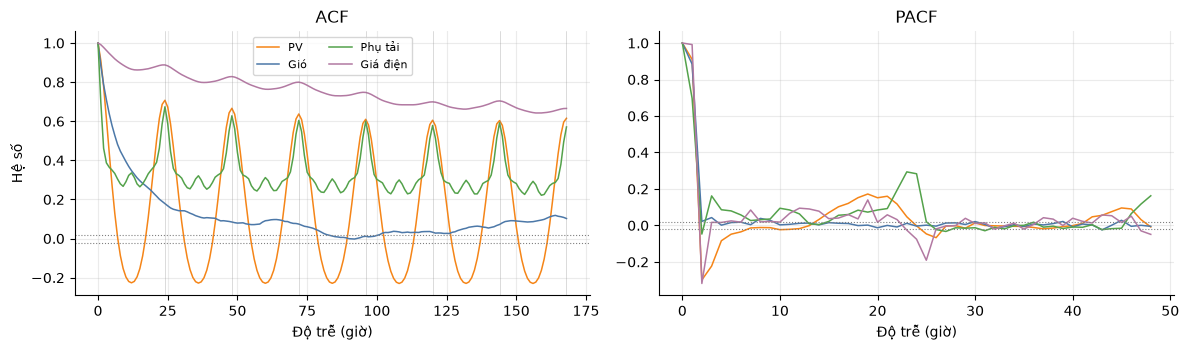

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for name in ts:
    ax[0].plot(acfs[name], lw=1.1, label=name, color=colors[name])
    ax[1].plot(pacfs[name], lw=1.1, label=name, color=colors[name])
band = 1.96 / np.sqrt(len(df))
for a in ax:
    a.axhline(band, color="grey", ls=":", lw=0.8)
    a.axhline(-band, color="grey", ls=":", lw=0.8)
for k in (24, 48, 72, 96, 120, 144, 168):
    ax[0].axvline(k, color="grey", lw=0.4, alpha=0.5)
ax[0].set(title="ACF", xlabel="Độ trễ (giờ)", ylabel="Hệ số")
ax[1].set(title="PACF", xlabel="Độ trễ (giờ)")
ax[0].legend(ncol=2, fontsize=8)
fig.tight_layout()
fig.savefig("hinh/eda_tutuongquan.png", dpi=200)
plt.show()